# Session 1: exploratory data analysis
Explore hourly electricity generation before choosing a forecasting model. We keep the last 48 observations as chronological validation; pattern analysis uses only earlier history. The supplied future weather contains no target values.


In [ ]:
# Run from the repository root so data and results paths resolve.
import os, sys
from pathlib import Path
if Path.cwd().name == 'notebooks':
    os.chdir('..')
sys.path.insert(0, str(Path.cwd()))
sys.path.insert(0, str(Path.cwd()/'scripts'))

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from statsmodels.graphics.tsaplots import plot_acf
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (12, 4)})
pd.set_option("display.max_columns", 20)
data = pd.read_csv("train.csv", parse_dates=["ds"])
weather_fc = pd.read_csv("weather_forecast.csv", parse_dates=["ds"])
H = 48
print(f"History: {len(data):,} rows, {data.ds.min()} to {data.ds.max()}")
print(f"Forecast: {len(weather_fc)} rows, {weather_fc.ds.min()} to {weather_fc.ds.max()}")
display(data.head())


History: 33,480 rows, 2023-01-01 01:00:00 to 2026-10-27 00:00:00
Forecast: 48 rows, 2026-10-27 01:00:00 to 2026-10-29 00:00:00


,ds,y,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
0,2023-01-01 01:00:00,30.1,0.0,-7,1,765,96,0,1.338069
1,2023-01-01 02:00:00,30.1,0.0,-7,1,765,96,0,1.338069
2,2023-01-01 03:00:00,19.2,0.0,-7,1,765,96,0,1.338069
3,2023-01-01 04:00:00,15.1,0.0,-7,1,765,96,0,1.338069
4,2023-01-01 05:00:00,21.9,0.0,-8,1,765,95,0,1.343119


## 1. Data integrity
Check timestamps before sorting or filling anything. Zero and negative generation need attention because MAPE divides by the actual value.

In [2]:
for name, frame in [("history", data), ("future weather", weather_fc)]:
    expected = pd.date_range(frame.ds.min(), frame.ds.max(), freq="h")
    print(name, {"duplicate_hours": int(frame.ds.duplicated().sum()),
                 "missing_hours": len(expected.difference(frame.ds)),
                 "ordered": frame.ds.is_monotonic_increasing})
    display(pd.DataFrame({"dtype": frame.dtypes.astype(str), "missing": frame.isna().sum()}))
    assert frame.ds.notna().all() and frame.ds.is_unique and frame.ds.is_monotonic_increasing
    assert len(expected.difference(frame.ds)) == 0
    assert np.isfinite(frame.select_dtypes("number")).all().all()
assert len(weather_fc) == H
assert weather_fc.ds.iloc[0] == data.ds.iloc[-1] + pd.Timedelta(hours=1)
print("Zero targets:", int(data.y.eq(0).sum()), "Negative targets:", int(data.y.lt(0).sum()))
train, valid = data.iloc[:-H].copy(), data.iloc[-H:].copy()
eda = train.assign(hour=train.ds.dt.hour, month=train.ds.dt.month,
                   weekday=train.ds.dt.dayofweek, year=train.ds.dt.year)
display(train.describe().T)


history {'duplicate_hours': 0, 'missing_hours': 0, 'ordered': True}


,dtype,missing
ds,datetime64[ns],0
y,float64,0
cloud_cover,float64,0
temperature,int64,0
wind_speed,int64,0
pressure,int64,0
humidity,int64,0
daylight,int64,0
air_density,float64,0


future weather {'duplicate_hours': 0, 'missing_hours': 0, 'ordered': True}


,dtype,missing
ds,datetime64[ns],0
cloud_cover,float64,0
temperature,int64,0
wind_speed,int64,0
pressure,int64,0
humidity,int64,0
daylight,int64,0
air_density,float64,0


Zero targets: 0 Negative targets: 0


,count,mean,min,25%,50%,75%,max,std
ds,33432,2024-11-27 12:30:00,2023-01-01 01:00:00,2023-12-15 06:45:00,2024-11-27 12:30:00,2025-11-10 18:15:00,2026-10-25 00:00:00,NaN
y,33432.0,315.744416,0.7,94.5,220.6,356.2,3111.3,377.655978
cloud_cover,33432.0,0.602963,0.0,0.25,0.75,1.0,1.0,0.418356
temperature,33432.0,12.228075,-19.0,4.0,12.0,21.0,39.0,10.671252
wind_speed,33432.0,3.728374,0.0,2.0,3.0,5.0,14.0,2.327655
pressure,33432.0,757.654822,736.0,754.0,757.0,761.0,775.0,5.538401
humidity,33432.0,71.671363,7.0,56.0,77.0,89.0,100.0,21.175205
daylight,33432.0,0.474785,0.0,0.0,0.0,1.0,1.0,0.499371
air_density,33432.0,1.237735,1.124386,1.197299,1.235298,1.275229,1.410444,0.050319


## 2. Trend, seasonality, and recent behavior
Daily means reduce visual clutter; the last two weeks show the hourly pattern. Group averages can mix weather and seasonal effects and are not causal estimates.

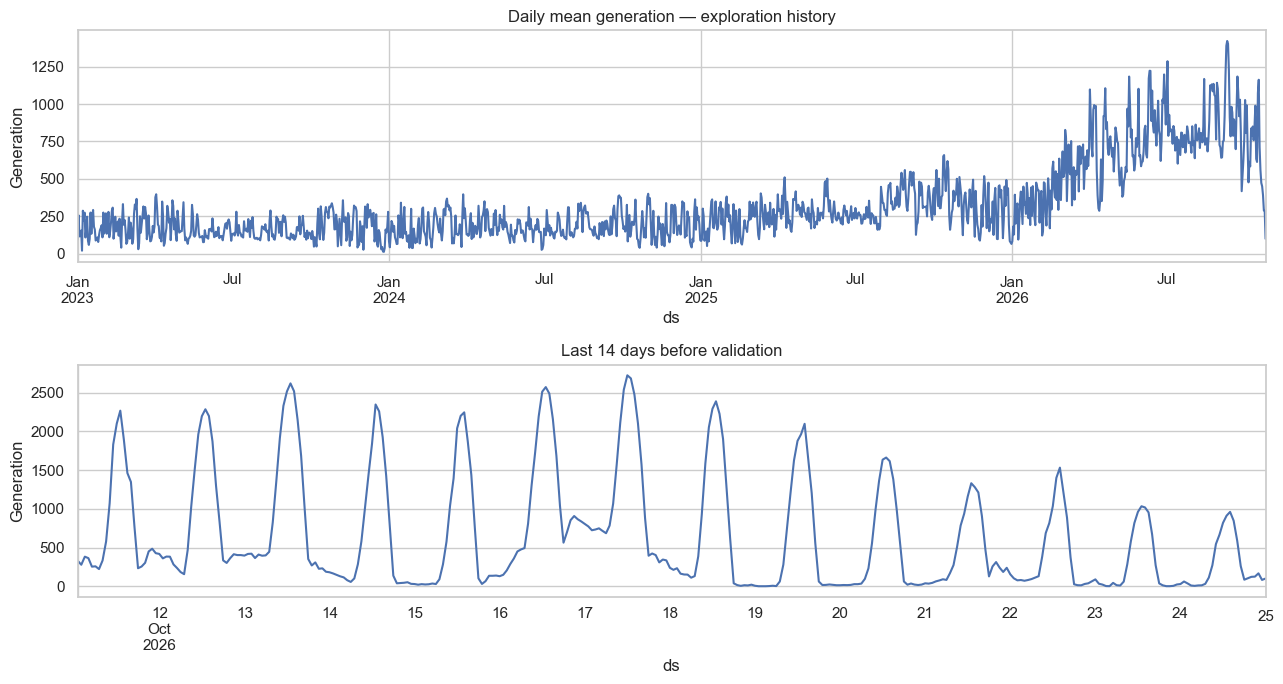

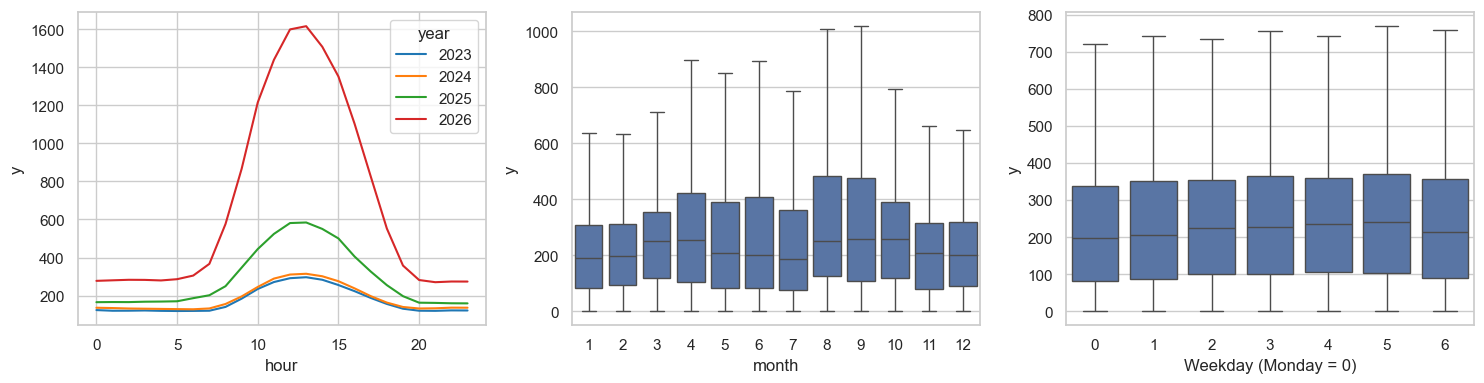

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
train.set_index("ds").y.resample("D").mean().plot(ax=axes[0], title="Daily mean generation — exploration history")
train.tail(14*24).plot(x="ds", y="y", ax=axes[1], title="Last 14 days before validation", legend=False)
for ax in axes: ax.set_ylabel("Generation")
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.lineplot(data=eda, x="hour", y="y", hue="year", errorbar=None, palette="tab10", ax=axes[0])
sns.boxplot(data=eda, x="month", y="y", showfliers=False, ax=axes[1])
sns.boxplot(data=eda, x="weekday", y="y", showfliers=False, ax=axes[2])
axes[2].set_xlabel("Weekday (Monday = 0)")
plt.tight_layout(); plt.show()


## 3. Distribution and serial dependence
Inspect daily (24-hour) and weekly (168-hour) persistence. ACF confidence bands are descriptive for this potentially nonstationary series.

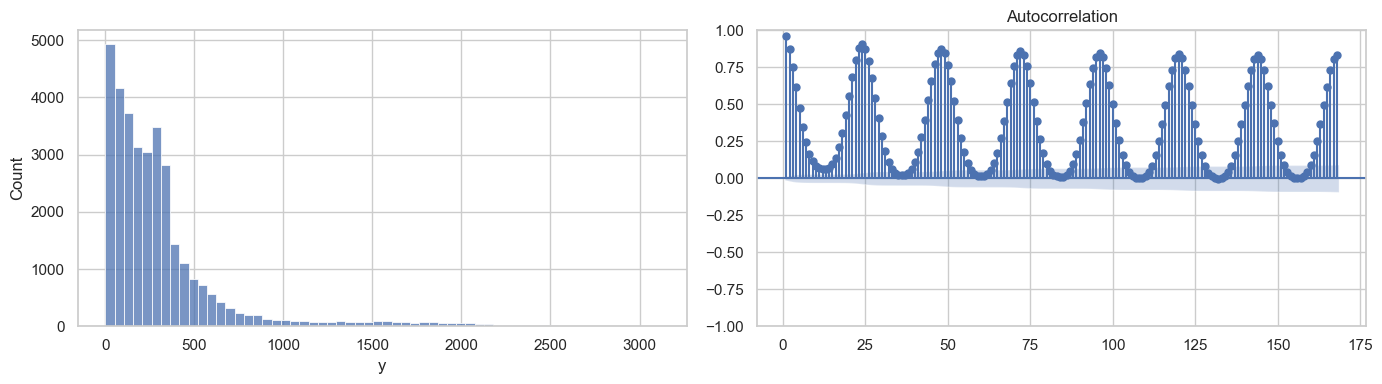

Lag (hours)
1      0.963628
24     0.905468
48     0.875738
168    0.836982
Name: Target autocorrelation, dtype: float64

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(train.y, bins=60, ax=axes[0])
plot_acf(train.y, lags=7*24, zero=False, ax=axes[1])
plt.tight_layout(); plt.show()
display(pd.Series({lag: train.y.autocorr(lag) for lag in [1, 24, 48, 168]}, name="Target autocorrelation").rename_axis("Lag (hours)"))


## 4. Weather and generation
Correlations and scatterplots suggest candidate predictors; they do not establish causality. Sampling is for plotting only.

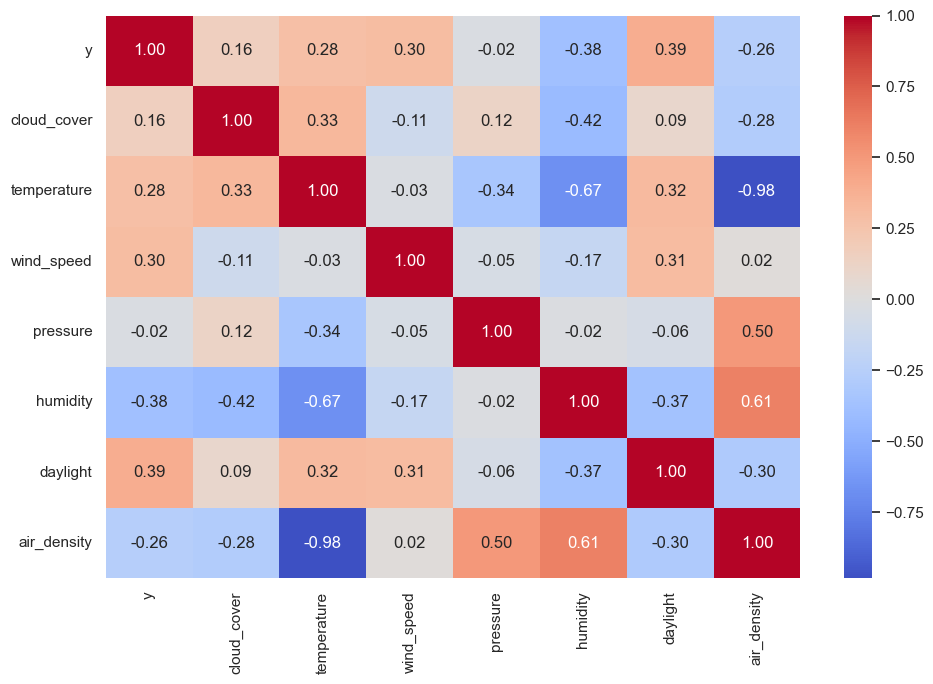

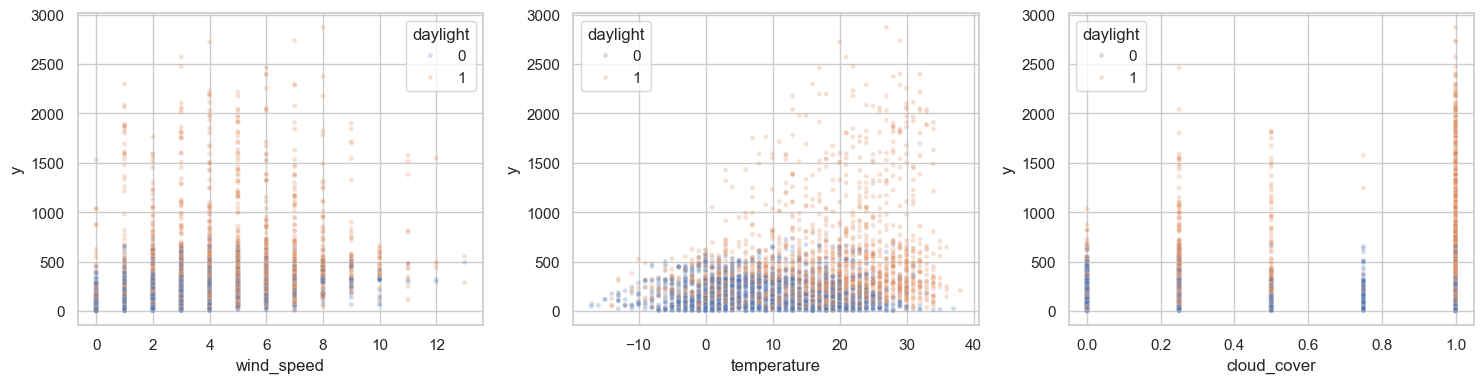

,count,mean,median,std
daylight,,,,
0,17559,174.262253,139.7,142.600070
1,15873,472.254545,315.1,480.906105


In [5]:
weather_cols = [c for c in weather_fc.columns if c != "ds"]
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(train[["y"] + weather_cols].corr(), annot=True, fmt=".2f", center=0, cmap="coolwarm", ax=ax)
plt.tight_layout(); plt.show()
sample = eda.sample(min(4000, len(eda)), random_state=42)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["wind_speed", "temperature", "cloud_cover"]):
    sns.scatterplot(data=sample, x=col, y="y", hue="daylight", alpha=.25, s=12, ax=ax)
plt.tight_layout(); plt.show()
display(eda.groupby("daylight").y.agg(["count", "mean", "median", "std"]))


## 5. Future weather versus recent history
Compare ranges to identify extrapolation. The final 48 historical hours are available at the actual forecast origin, but were excluded from the earlier exploratory plots.

,recent_min,recent_mean,recent_max,future_min,future_mean,future_max
cloud_cover,0.000000,0.493304,1.000000,0.0000,0.614583,1.0000
temperature,4.000000,12.502976,24.000000,4.0000,9.041667,19.0000
wind_speed,0.000000,2.184524,7.000000,0.0000,2.562500,4.0000
pressure,759.000000,762.622024,765.000000,755.0000,760.500000,764.0000
humidity,34.000000,87.732143,100.000000,60.0000,95.833333,100.0000
daylight,0.000000,0.392857,1.000000,0.0000,0.375000,1.0000
air_density,1.190573,1.243009,1.281574,1.2015,1.255983,1.2876


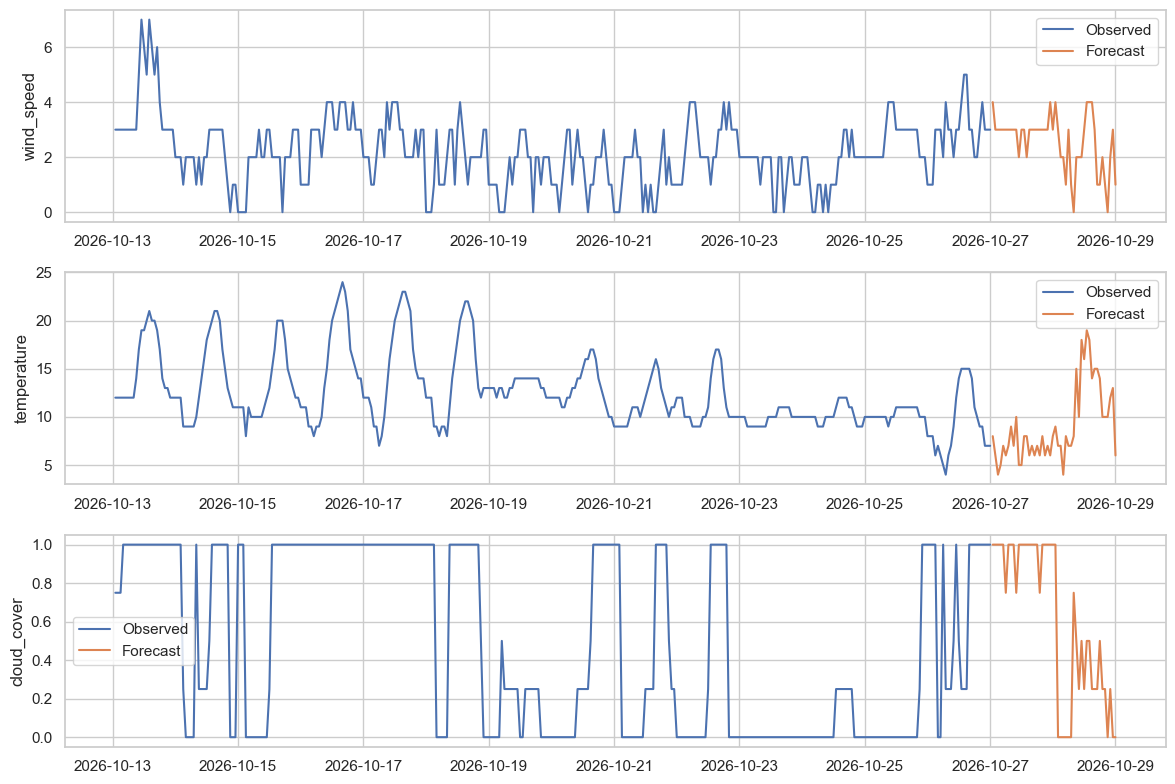

In [6]:
recent = data.tail(14*24)
comparison = pd.DataFrame({"recent_min": recent[weather_cols].min(), "recent_mean": recent[weather_cols].mean(),
                           "recent_max": recent[weather_cols].max(), "future_min": weather_fc[weather_cols].min(),
                           "future_mean": weather_fc[weather_cols].mean(), "future_max": weather_fc[weather_cols].max()})
display(comparison)
fig, axes = plt.subplots(3, 1, figsize=(12, 8))
for ax, col in zip(axes, ["wind_speed", "temperature", "cloud_cover"]):
    ax.plot(recent.ds, recent[col], label="Observed")
    ax.plot(weather_fc.ds, weather_fc[col], label="Forecast")
    ax.set_ylabel(col); ax.legend()
plt.tight_layout(); plt.show()


## 6. Session 1 benchmark on the held-out 48 hours
Repeat the last training day twice, using the assignment’s seasonal-naive interval. This gives a reference score, not a chosen final model. One validation window is noisy; use multiple rolling origins for model selection.

,Seasonal naive
RMSE,120.404317
MAPE (%),51.088040
Winkler,568.463586
Coverage,1.000000


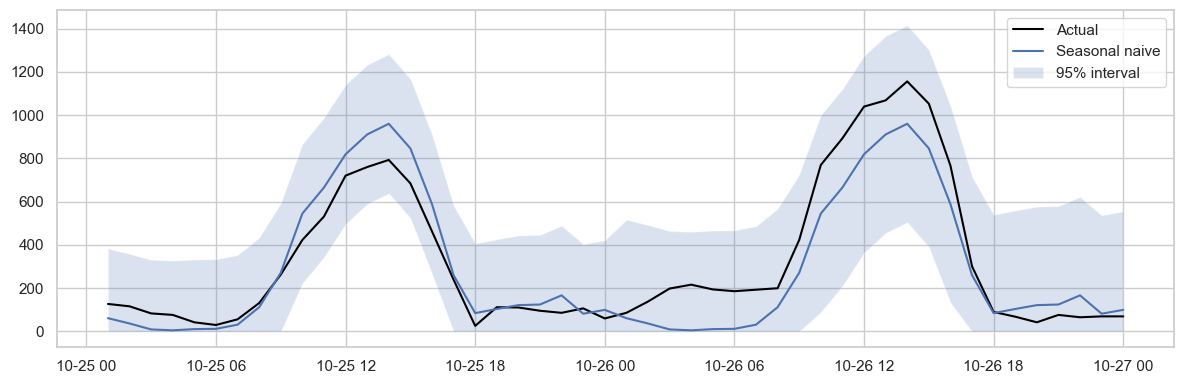

In [7]:
history = train.y.to_numpy(float)
actual = valid.y.to_numpy(float)
point = np.tile(history[-24:], 2)
sigma = np.std(history[24:] - history[:-24], ddof=1)
half = 1.96 * sigma * np.sqrt(np.arange(H)//24 + 1)
lower, upper = np.clip(point-half, 0, None), point+half
scores = pd.Series({
    "RMSE": np.sqrt(np.mean((actual-point)**2)),
    "MAPE (%)": np.mean(np.abs((actual-point)/actual))*100 if np.all(actual != 0) else np.nan,
    "Winkler": np.mean(upper-lower + 40*np.clip(lower-actual, 0, None) + 40*np.clip(actual-upper, 0, None)),
    "Coverage": np.mean((actual >= lower) & (actual <= upper))
}, name="Seasonal naive")
display(scores.to_frame())
fig, ax = plt.subplots()
ax.plot(valid.ds, actual, label="Actual", color="black")
ax.plot(valid.ds, point, label="Seasonal naive")
ax.fill_between(valid.ds, lower, upper, alpha=.2, label="95% interval")
ax.legend(); plt.tight_layout(); plt.show()


## Next steps
- Use the observed seasonal patterns and weather relationships to choose candidate features.
- Compare candidates with seasonal naive using rolling 48-hour validation windows, fitting preprocessing on each training window only.
- Lag features beyond the forecast origin must use predictions or known historical values, never held-out targets.
- Historical weather is observed; future weather is forecast with errors that grow on day two. Validation with observed weather is optimistic.
- Select the model and interval method using validation, then refit on all history and generate the submission in the original notebook.
